In [1]:
import matplotlib.pyplot as plt
import numpy as np

from superfv import HydroSolverOutput

base_path = "/scratch/gpfs/jp7427/out/isotropic-decaying-turbulence/"


In [2]:
def isotropic_2d_spectrum(vx, vy, rho=None, dx=1.0, dy=1.0, density_weighted=True, nbins=None):
    """
    Compute isotropic shell-integrated 2D kinetic energy spectrum E(k)

    Parameters
    ----------
    vx, vy : ndarray, shape (nx, ny)
        Velocity components
    rho : ndarray, optional, shape (nx, ny)
        Density field; used for density-weighted KE
    dx, dy : float
        Grid spacing
    density_weighted : bool
        If True and rho is given, use sqrt(rho)*v for KE
    nbins : int, optional
        Number of radial bins in k-space

    Returns
    -------
    k_centers : ndarray
        Radial wavenumber bin centers
    E_k : ndarray
        Shell-integrated kinetic energy per bin
    """

    nx, ny = vx.shape
    assert vy.shape == (nx, ny)
    if rho is not None and density_weighted:
        wx = np.sqrt(np.maximum(rho, 0)) * vx
        wy = np.sqrt(np.maximum(rho, 0)) * vy
    else:
        wx, wy = vx, vy

    # 2D FFT, normalized to match Parseval
    wx_hat = np.fft.fft2(wx) / (nx * ny)
    wy_hat = np.fft.fft2(wy) / (nx * ny)

    # Kinetic energy per mode
    ke_hat_sq = 0.5 * (np.abs(wx_hat) ** 2 + np.abs(wy_hat) ** 2)

    # Wavenumber grids
    kx = 2 * np.pi * np.fft.fftfreq(nx, dx)
    ky = 2 * np.pi * np.fft.fftfreq(ny, dy)
    kx, ky = np.meshgrid(kx, ky, indexing="ij")
    k = np.sqrt(kx**2 + ky**2)

    # Flatten for binning
    k_flat = k.ravel()
    ke_flat = ke_hat_sq.ravel()

    if nbins is None:
        nbins = min(nx, ny) // 2

    kmax = max(kx.max(), ky.max())  # k_flat.max()
    nbins = nx // 2
    bins = np.linspace(0.0, kmax, nbins + 1)

    E_k, _ = np.histogram(k_flat, bins=bins, weights=ke_flat)

    # bin_idx = np.digitize(k_flat, bins) - 1

    # # Shell-integrated E(k)
    # E_k = np.zeros(nbins)
    # for i in range(ke_flat.size):
    #     b = bin_idx[i]
    #     if 0 <= b < nbins:
    #         E_k[b] += ke_flat[i]  # sum energy in shell

    # Radial bin centers
    k_centers = 0.5 * (bins[:-1] + bins[1:])
    dk = bins[1:] - bins[:-1]

    return k_centers, E_k / dk

In [3]:
sim_cache = {}


def plot_spectra(path, ax, style=None, n=-1, M_max=1):
    if path in sim_cache:
        sim = sim_cache[path]
    else:
        sim = HydroSolverOutput(path)
        sim_cache[path] = sim

    idx = sim.params.variable_index_map
    mesh = sim.mesh
    w = sim.snapshot_history[n].w

    k_centers, E_k = isotropic_2d_spectrum(
        w[idx("vx")][:, :, 0],
        w[idx("vy")][:, :, 0],
        # rho=w[idx("rho")][:, :, 0],
        dx=mesh.hx,
        dy=mesh.hy,
    )

    ax.plot(k_centers[1:], E_k[1:] / M_max**2, linewidth=2, **(style if style is not None else dict()))

In [4]:
plt.rcParams['font.size'] = 14

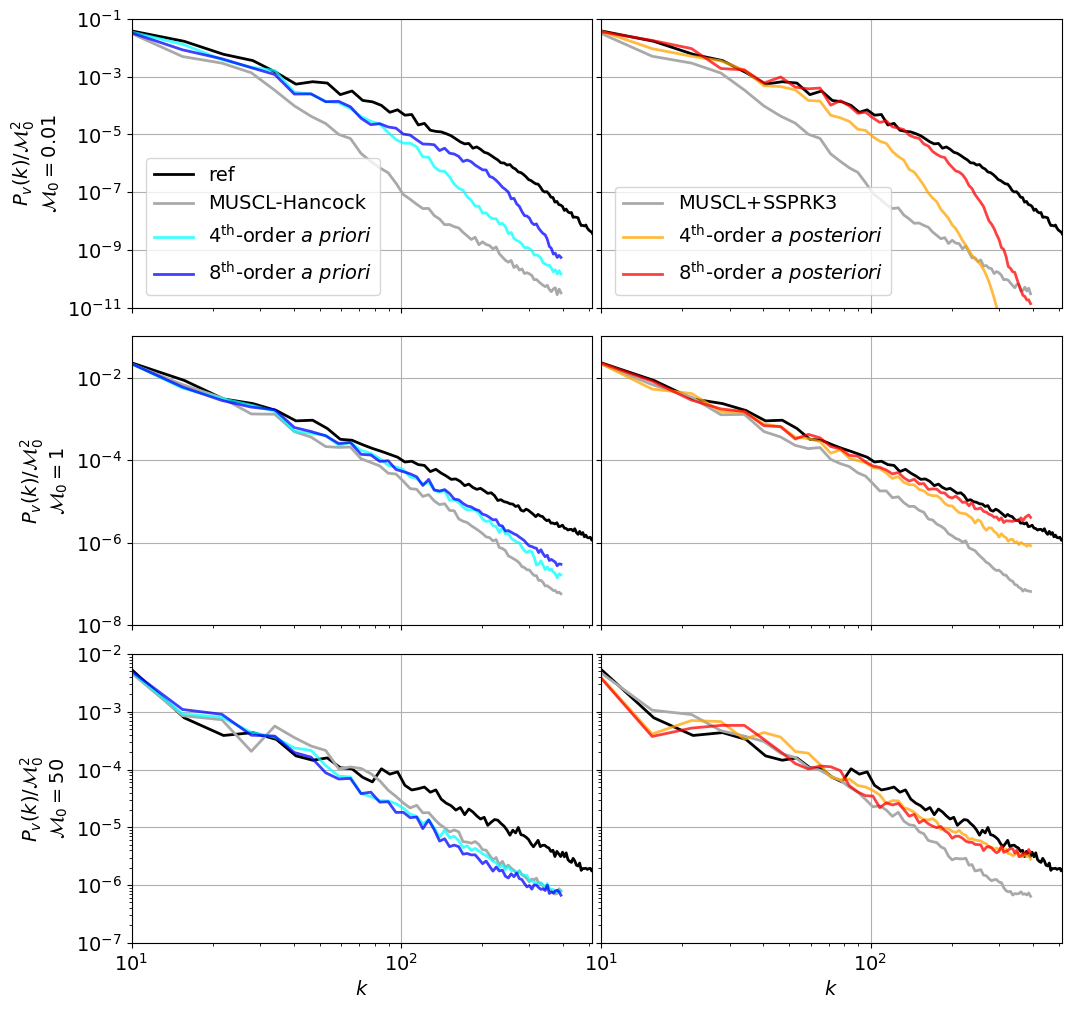

In [8]:
M_max_values = [0.01, 1, 50]
N = 128
seed = 1

fig, axs = plt.subplots(
    len(M_max_values),
    2,
    sharex=True,
    sharey="row",
    figsize=(12, 12),
)
for i in range(len(M_max_values)):
    axs[i, 0].set_xscale("log")
    axs[i, 0].set_yscale("log")
    for j in [0, 1]:
        axs[i, j].grid()

axs[-1, 0].set_xlabel(r"$k$")
axs[-1, 1].set_xlabel(r"$k$")

axs[0, 0].set_xlim(1e1, 4 * N)

axs[0, 0].set_ylim(1e-11, 1e-1)
axs[1, 0].set_ylim(1e-8, 1e-1)
axs[2, 0].set_ylim(1e-7, 1e-2)

for i, M in enumerate(M_max_values):
    # axs[i, 0].set_ylabel(r"$E_k / \rho \mathcal{M}_{0}^2$")
    axs[i, 0].set_ylabel(r"$P_v(k)/\mathcal{M}^2_{0}$" "\n" r"$\mathcal{M}_{0}=" + f"{M}$")

cmap1 = plt.get_cmap("GnBu")
cmap2 = plt.get_cmap("OrRd")

for i, M_max in enumerate(M_max_values):
    # MUSCL-Hancock / MUSCL-RK3
    plot_spectra(
        f"{base_path}ref/M_max_{M_max}/seed_{seed:02d}",
        axs[i, 0],
        style=dict(label="ref", color="black"),
        M_max=M_max,
    )
    plot_spectra(
        f"{base_path}ref/M_max_{M_max}/seed_{seed:02d}",
        axs[i, 1],
        style=dict(label="_nolegend_", color="black"),
        M_max=M_max,
    )
    plot_spectra(
        f"{base_path}MUSCL-Hancock/M_max_{M_max}/seed_{seed:02d}",
        axs[i, 0],
        style=dict(label="MUSCL-Hancock", color="darkgrey"),
        M_max=M_max,
    )
    plot_spectra(
        f"{base_path}MUSCL-RK3/M_max_{M_max}/seed_{seed:02d}",
        axs[i, 1],
        style=dict(label="MUSCL$+$SSPRK3", color="darkgrey"),
        M_max=M_max,
    )

    # a priori
    plot_spectra(
        f"{base_path}ZS3/M_max_{M_max}/seed_{seed:02d}",
        axs[i, 0],
        style=dict(label=r"$4^{\mathrm{th}}$-order $\mathit{a\ priori}$", color="cyan", alpha=0.75),
        M_max=M_max,
    )
    plot_spectra(
        f"{base_path}ZS7/M_max_{M_max}/seed_{seed:02d}",
        axs[i, 0],
        style=dict(label=r"$8^{\mathrm{th}}$-order $\mathit{a\ priori}$", color="blue", alpha=0.75),
        M_max=M_max,
    )

    # a posteriori
    if M_max <= 1:
        plot_spectra(
            f"{base_path}MM3/1rev/rtol_1e-1/M_max_{M_max}/seed_{seed:02d}",
            axs[i, 1],
            style=dict(label=r"$4^{\mathrm{th}}$-order $\mathit{a\ posteriori}$", color="orange", alpha=0.75),
            M_max=M_max,
        )
        plot_spectra(
            f"{base_path}MM7/1rev/rtol_1e-1/M_max_{M_max}/seed_{seed:02d}",
            axs[i, 1],
            style=dict(label=r"$8^{\mathrm{th}}$-order $\mathit{a\ posteriori}$", color="red", alpha=0.75),
            M_max=M_max,
        )
    else:
        plot_spectra(
            f"{base_path}MM3/3revs/rtol_1e-1/M_max_{M_max}/seed_{seed:02d}",
            axs[i, 1],
            style=dict(label=r"$4^{\mathrm{th}}$-order $\mathit{a\ posteriori}$", color="orange", alpha=0.75),
            M_max=M_max,
        )
        plot_spectra(
            f"{base_path}MM7/3revs/rtol_1e-1/M_max_{M_max}/seed_{seed:02d}",
            axs[i, 1],
            style=dict(label=r"$8^{\mathrm{th}}$-order $\mathit{a\ posteriori}$", color="red", alpha=0.75),
            M_max=M_max,
        )

plt.subplots_adjust(wspace=0.02, hspace=0.1)

axs[0, 0].legend(loc="lower left", bbox_to_anchor=(0.01, 0.01))
axs[0, 1].legend(loc="lower left", bbox_to_anchor=(0.01, 0.01))

fig.savefig("spectra_talk.pdf", bbox_inches="tight")